In [3]:
import pandas as pd

In [ ]:
df = pd.read_csv(r'D:\Download\E-Commerce Customer\2019-Oct.csv')
df.shape

In [11]:
df_sample = df.sample(n=500000, random_state=42)
df_sample.shape

(500000, 9)

In [12]:
df_sample['event_time'].min(), df_sample['event_time'].max()

('2019-10-01 00:00:24 UTC', '2019-10-31 23:58:27 UTC')

In [13]:
# Fill missing category_code and brand with "Unknown"
df_sample['category_code'] = df_sample['category_code'].fillna('Unknown')
df_sample['brand'] = df_sample['brand'].fillna('Unknown')

df_sample.isnull().sum()

event_time       0
event_type       0
product_id       0
category_id      0
category_code    0
brand            0
price            0
user_id          0
user_session     0
dtype: int64

In [14]:
df_sample.to_csv(r'D:\Download\E-Commerce Customer\ecommerce_full_month_sample.csv', index=False)

In [20]:
purchases = df_sample[df_sample['event_type'] == 'purchase']

# Convert event_time to proper datetime format
purchases['event_time'] = pd.to_datetime(purchases['event_time'])

# Find each user's last purchase date
last_purchase = purchases.groupby('user_id')['event_time'].max().reset_index()
last_purchase.columns = ['user_id', 'last_purchase_date']

last_purchase.head()

C:\Users\ankit\AppData\Local\Temp\ipykernel_3300\1131650380.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  purchases['event_time'] = pd.to_datetime(purchases['event_time'])


,user_id,last_purchase_date
0,439111345,2019-10-04 05:31:31+00:00
1,446080337,2019-10-18 06:34:47+00:00
2,460983696,2019-10-04 06:02:48+00:00
3,468406319,2019-10-25 04:24:49+00:00
4,488123390,2019-10-03 07:16:27+00:00


In [21]:
churn_summary = last_purchase['churn_status'].value_counts()
churn_summary

KeyError: 'churn_status'

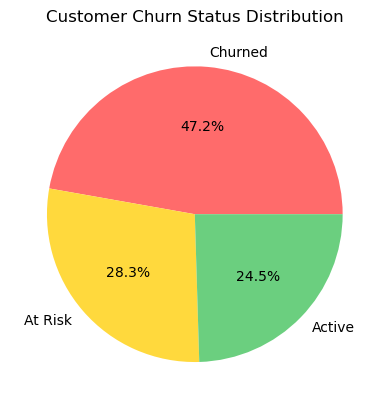

In [22]:
import matplotlib.pyplot as plt

# Create pie chart for churn distribution
churn_summary.plot(kind='pie', autopct='%1.1f%%', colors=['#ff6b6b', '#ffd93d', '#6bcf7f'])
plt.title('Customer Churn Status Distribution')
plt.ylabel('')  # removes default y-label
plt.show()

In [18]:
import datetime

reference_date = pd.to_datetime('2019-10-31 23:59:59').tz_localize('UTC')

# Calculate days since last purchase
last_purchase['days_since_last_purchase'] = (reference_date - last_purchase['last_purchase_date']).dt.days

# Create churn status based on recency
def churn_label(days):
    if days <= 7:
        return 'Active'
    elif days <= 15:
        return 'At Risk'
    else:
        return 'Churned'

last_purchase['churn_status'] = last_purchase['days_since_last_purchase'].apply(churn_label)

last_purchase.head(10)

,user_id,last_purchase_date,days_since_last_purchase,churn_status
0,439111345,2019-10-04 05:31:31+00:00,27,Churned
1,446080337,2019-10-18 06:34:47+00:00,13,At Risk
2,460983696,2019-10-04 06:02:48+00:00,27,Churned
3,468406319,2019-10-25 04:24:49+00:00,6,Active
4,488123390,2019-10-03 07:16:27+00:00,28,Churned
5,497226076,2019-10-20 08:57:46+00:00,11,At Risk
6,502364367,2019-10-04 06:26:36+00:00,27,Churned
7,503309480,2019-10-30 07:48:43+00:00,1,Active
8,506224239,2019-10-23 08:11:12+00:00,8,At Risk
9,508837205,2019-10-19 13:58:15+00:00,12,At Risk


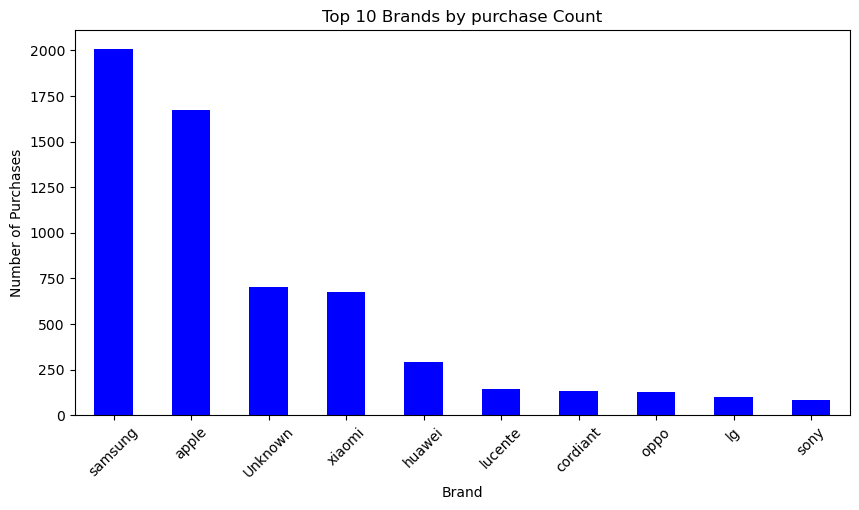

In [13]:
purchases = df_sample[df_sample['event_type'] == 'purchase']

top_brands = purchases['brand'].value_counts().head(10)

top_brands.plot(kind='bar',color='Blue',figsize=(10,5))
plt.title('Top 10 Brands by purchase Count')
plt.xlabel('Brand')
plt.ylabel('Number of Purchases')
plt.xticks(rotation=45)
plt.show()

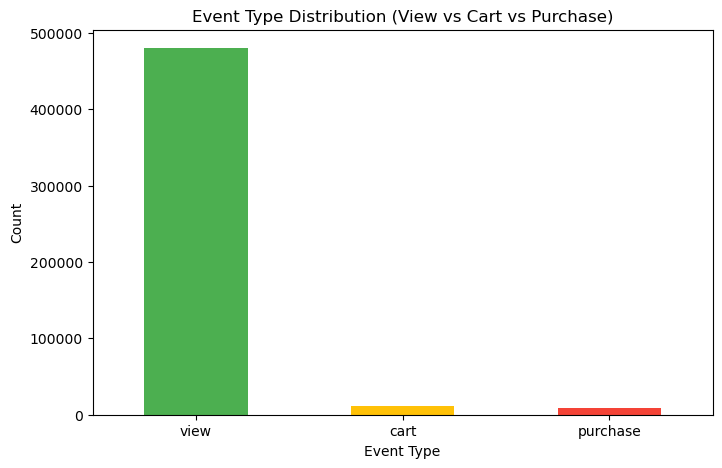

In [14]:
# Event type distribution
event_counts = df_sample['event_type'].value_counts()

# Plot as bar chart
event_counts.plot(kind='bar', color=['#4CAF50', '#FFC107', '#F44336'], figsize=(8,5))
plt.title('Event Type Distribution (View vs Cart vs Purchase)')
plt.xlabel('Event Type')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

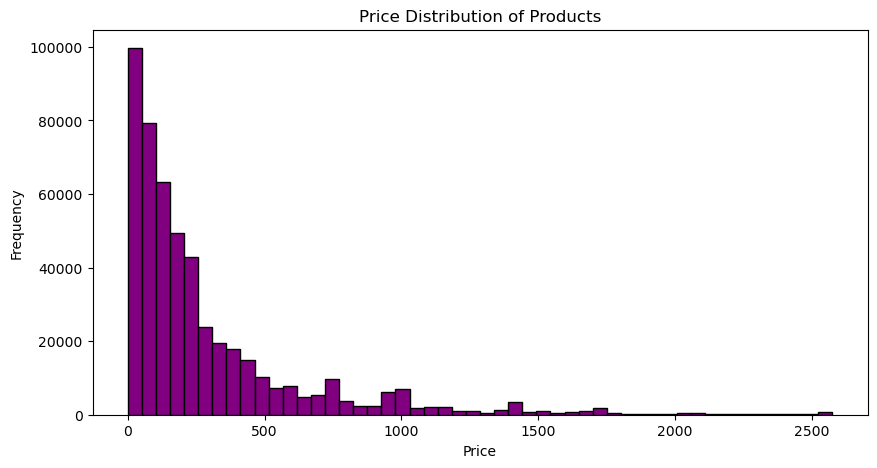

In [15]:
plt.figure(figsize=(10,5))
plt.hist(df_sample['price'], bins=50, color='purple', edgecolor='black')
plt.title('Price Distribution of Products')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

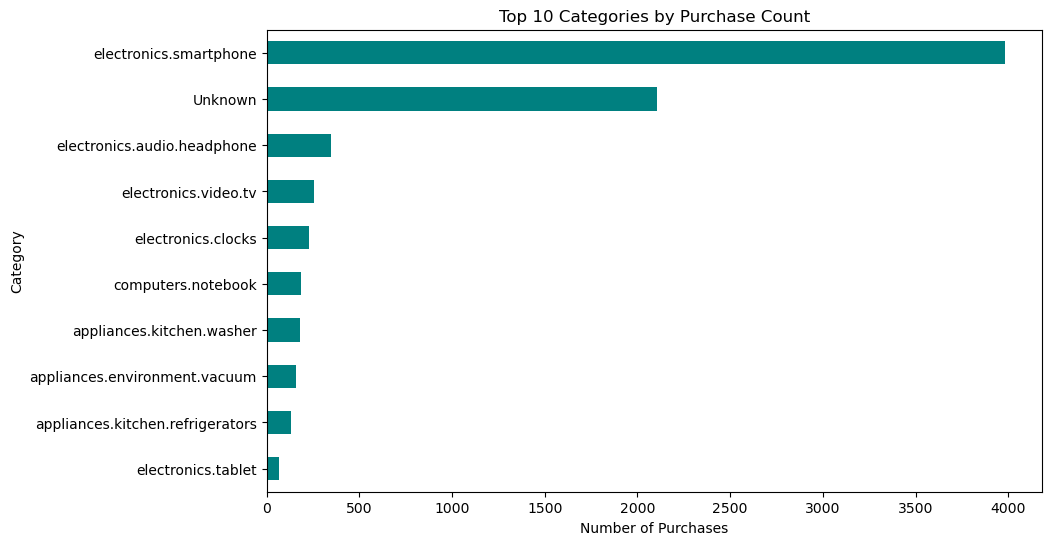

In [16]:
top_categories = purchases['category_code'].value_counts().head(10)

top_categories.plot(kind='barh', color='teal', figsize=(10,6))
plt.title('Top 10 Categories by Purchase Count')
plt.xlabel('Number of Purchases')
plt.ylabel('Category')
plt.gca().invert_yaxis()  # highest value on top
plt.show()

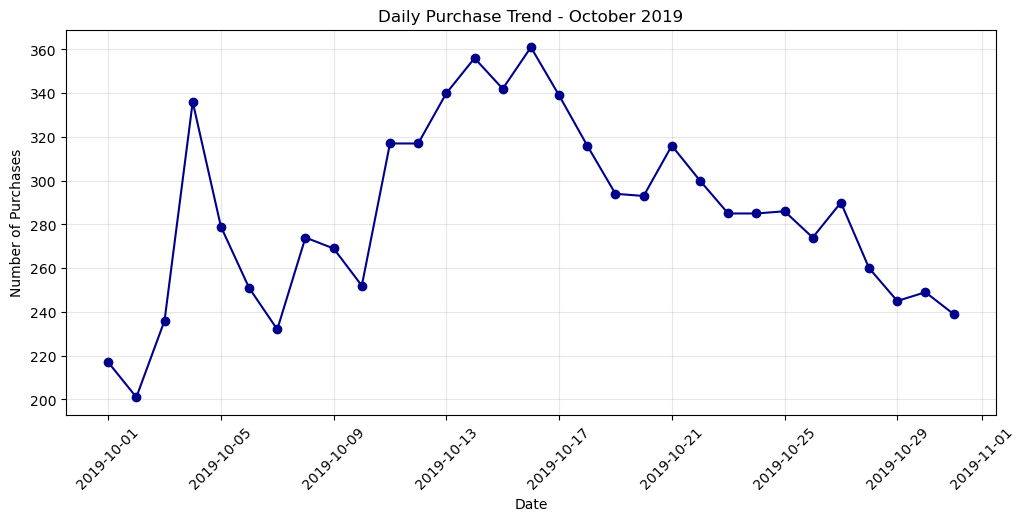

In [22]:
purchases = df_sample[df_sample['event_type'] == 'purchase'].copy()

purchases['event_time'] = pd.to_datetime(purchases['event_time'])

purchases['purchase_date'] = purchases['event_time'].dt.date

daily_purchases = purchases.groupby('purchase_date').size()

daily_purchases.plot(kind='line', marker='o', color='darkblue', figsize=(12,5))
plt.title('Daily Purchase Trend - October 2019')
plt.xlabel('Date')
plt.ylabel('Number of Purchases')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.show()      

In [24]:
print("=" * 50)
print("E-Commerce Churn Analysis")
print("=" * 50)

print(f"\n1. Dataset: {len(df_sample)} rows sampled from full October 2019 data")
print(f"   Date range: {purchases['event_time'].min()} to {purchases['event_time'].max()}")

print(f"\n2. Churn Analysis:")
print(churn_summary)

print(f"\n3. Total unique customers analyzed: {len(last_purchase)}")

print(f"\n4. Top Category: {top_categories.index[0]} ({top_categories.iloc[0]} purchases)")

print(f"\n5. Top Brand: {top_brands.index[0]} ({top_brands.iloc[0]} purchases)")

E-Commerce Churn Analysis

1. Dataset: 500000 rows sampled from full October 2019 data
   Date range: 2019-10-01 02:32:44+00:00 to 2019-10-31 23:56:03+00:00

2. Churn Analysis:
churn_status
Churned    4030
At Risk    2413
Active     2093
Name: count, dtype: int64

3. Total unique customers analyzed: 8536

4. Top Category: electronics.smartphone (3981 purchases)

5. Top Brand: samsung (2010 purchases)


In [25]:
last_purchase.to_csv(r'D:\Download\E-Commerce Customer\churn_analysis_result.csv', index=False)

print("Churn analysis saved successfully!")

Churn analysis saved successfully!


In [1]:
df_sample['category_code'] = df_sample['category_code'].fillna('Unknown')
df_sample['brand'] = df_sample['brand'].fillna('Unknown')

# Yahan turant save karna chahiye tha
df_sample.to_csv(r'D:\Download\E-Commerce Customer\ecommerce_full_month_sample.csv', index=False)

NameError: name 'df_sample' is not defined